# DQI cho bài gán teacher: từ dữ liệu tới kết quả

Notebook đi qua toàn bộ quy trình Decoded Quantum Interferometry (DQI, Jordan et al., arXiv:2408.08292) cho bài gán teacher cho section của ttqaoa: đọc dữ liệu, viết bài toán thành max-LINSAT, dựng mạch, giải mã, đo và chấm kết quả.

Phần 1 đến 10 dùng ví dụ 4 section, 3 teacher của NOTE-001. Ví dụ đủ nhỏ để chạy mạch thật (26 qubit) và đo từng thanh ghi sau mỗi bước, nên mỗi bước đều có một ô kiểm tra so với công thức. Phần 11 chạy lại trên `inst_01` của ttqaoa, có quota, để thấy những gì thay đổi trên dữ liệu thật.

Mỗi phần ghi mục tiêu, input, output, phương pháp, và lý do hay cách kiểm tra khi có. Giải thích dài hơn ở Notion: [NOTE-004](https://app.notion.com/p/3fa52101ba7581d7ab48da4dbef9dcc7) (DQI trên bài này) và [NOTE-003](https://app.notion.com/p/3fa52101ba758118b109c68ef8a94d8e) (DQI tổng quát, ví dụ của tutorial PennyLane). Kết quả trên cả 20 instance ở [RES-001](https://app.notion.com/p/3fa52101ba75819ba6afdffcf3f0135b).

| Phần | Nội dung | Code |
|---|---|---|
| 1 | Dữ liệu thô | file CSV |
| 2 | Xử lý dữ liệu | `problem.load` |
| 3 | Formulation max-LINSAT | `problem.build` |
| 4 | Code mà decoder phải giải | `problem.code_distance`, `decoder_failure` |
| 5 | Bước 1 của DQI: trọng số | `dqi.ideal_state` |
| 6 | Bước 2: Dicke state | stage `dicke` của `circuit.DQICircuit` |
| 7 | Bước 3, 4: nạp giá trị | stage `load` |
| 8 | Bước 5: syndrome | stage `syndrome` |
| 9 | Bước 6: giải mã | stage `decode` |
| 10 | Bước 7: Fourier, đo, chấm điểm | stage `qft` |
| 11 | Dữ liệu ttqaoa có quota | `formulations`, `classical` |

Chạy với `uv sync --all-groups`. Dữ liệu đọc từ `$DQITT_DATA` (mặc định `/home/al/Data`).

In [1]:
import csv
import math
import time
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
from loguru import logger

from dqitt import paths
from dqitt.circuit import DQICircuit, n_wires, row_coeffs
from dqitt.classical import cpsat_optimum, optimum
from dqitt.dqi import all_x, expected_satisfied, ideal_state, l1_probs, l1_weights, theory_weights
from dqitt.formulations import binary, to_assignment
from dqitt.metrics import shots_to_hit
from dqitt.problem import brute_force, build, code_distance, decoder_failure, error_patterns, load, violations

logger.remove()
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)
DATA = paths.DATA / "dqitt" / "note001"
print(DATA)

/home/al/Data/dqitt/note001


## 1. Dữ liệu thô

**Mục tiêu.** Xem đúng những gì bài toán nhận vào.

**Input.** 4 file CSV theo layout của ttqaoa: `Task` (section, môn, slot), `InstructorSkill` (điểm kỹ năng của teacher theo môn), `InstructorSlot` (mức rảnh theo slot), `SlotConflict` (slot nào trùng giờ slot nào). Ví dụ này không có `InstructorQuota`.

**Output.** Nội dung các file.

In [2]:
for name in ["Task.csv", "InstructorSkill.csv", "InstructorSlot.csv", "SlotConflict.csv"]:
    print(f"--- {name}\n{(DATA / name).read_text()}")

--- Task.csv
Class,Subject,Slot
s0,SUB0,MON_AM
s1,SUB1,MON_AM
s2,SUB2,MON_AM
s3,SUB3,TUE_PM

--- InstructorSkill.csv
,SUB0,SUB1,SUB2,SUB3
An,5,0,5,5
Binh,5,5,5,0
Chi,0,5,5,5

--- InstructorSlot.csv
,MON_AM,TUE_PM
An,5,5
Binh,5,5
Chi,5,5

--- SlotConflict.csv
,MON_AM,TUE_PM
MON_AM,1,0
TUE_PM,0,1



## 2. Xử lý dữ liệu

**Mục tiêu.** Rút từ 4 bảng ra hai thứ bài toán dùng: tập teacher dạy được mỗi section, và các cặp section trùng giờ.

**Input.** Các file CSV ở phần 1.

**Output.** Một `Instance`: `eligible[s]` là tập $E_s$, `conflicts` là danh sách cặp $(s,s')$, `quota` nếu có file quota.

**Phương pháp.** Teacher $t$ dạy được section $s$ khi điểm kỹ năng môn của $s$ và mức rảnh ở slot của $s$ đều từ 5 trở lên, cùng ngưỡng với `TimetableProblem` của ttqaoa. Môn hay slot không có trong bảng được tính là 0, như ttqaoa. Hai section conflict khi ô `SlotConflict` của hai slot bằng 1.

**Lý do.** Sau bước này mọi bước sau chỉ dùng $E_s$, các cặp conflict và quota; không cần quay lại bảng gốc.

In [3]:
inst = load(DATA)
T = inst.teachers
for sec, slot, E in zip(inst.sections, inst.slots, inst.eligible):
    print(f"{sec} (slot {slot}): eligible = {[T[t] for t in sorted(E)]}")
print("conflict:", [(inst.sections[a], inst.sections[b]) for a, b in inst.conflicts])
print("quota:", inst.quota)

s0 (slot MON_AM): eligible = ['An', 'Binh']
s1 (slot MON_AM): eligible = ['Binh', 'Chi']
s2 (slot MON_AM): eligible = ['An', 'Binh', 'Chi']
s3 (slot TUE_PM): eligible = ['An', 'Chi']
conflict: [('s0', 's1'), ('s0', 's2'), ('s1', 's2')]
quota: None


Đồ thị conflict: mỗi đỉnh là một section, cạnh nối hai section trùng giờ, nhãn là các teacher dạy được.

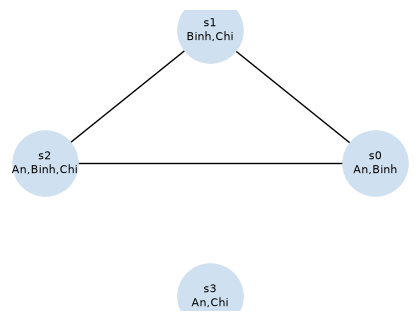

In [4]:
G = nx.Graph()
G.add_nodes_from(inst.sections)
G.add_edges_from((inst.sections[a], inst.sections[b]) for a, b in inst.conflicts)
labels = {sec: f"{sec}\n{','.join(T[t] for t in sorted(E))}" for sec, E in zip(inst.sections, inst.eligible)}
plt.figure(figsize=(4, 3))
nx.draw(G, nx.circular_layout(G), labels=labels, node_color="#cfe0f0", node_size=2200, font_size=8)
plt.show()

## 3. Formulation: viết bài toán thành max-LINSAT

**Mục tiêu.** Đưa bài toán về dạng DQI nhận: bộ $(p,B,F)$. Lịch $y\in\mathbb{F}_p^n$ thoả row $i$ khi $b_i\cdot y \bmod p\in F_i$, và ta muốn thoả nhiều row nhất (Def. 2.1 của Jordan et al.).

**Input.** `Instance` ở phần 2.

**Output.** `Linsat`: số nguyên tố $p$, ma trận $B$ cỡ $m\times n$, các tập $F_i$.

**Phương pháp.**
- Biến $y_s$ là teacher của section $s$, nên $n$ là số section. $p$ là số nguyên tố nhỏ nhất $\ge$ số teacher; giá trị dư ra là teacher ảo.
- Mỗi cặp conflict $(a,b)$ cho row $y_a+(p-1)y_b$, tức $y_a-y_b$, với $F=\{1,\dots,p-1\}$: row thoả khi hai section khác teacher.
- Mỗi section cho row $y_s$ với $F=E_s$; bỏ row nếu mọi giá trị đều thuộc $E_s$, vì row đó luôn thoả.

**Lý do.** Mỗi section chỉ có một biến nên ràng buộc "đúng một teacher" tự thoả. Phép mod $p$ đến từ DQI: các bước Fourier và giải mã làm trên $\mathbb{F}_p$, nên $p$ phải nguyên tố. Quota là phép đếm số section của một teacher, không viết được thành một row tuyến tính theo $y$; phần 11 dùng encoding khác cho quota.

In [5]:
lin = build(inst)
print(f"p = {lin.p}, n = {lin.n} biến, m = {lin.m} row")
meaning = [f"conflict {inst.sections[a]}-{inst.sections[b]}" for a, b in inst.conflicts] + [
    f"eligibility {inst.sections[s]}" for s, E in enumerate(inst.eligible) if 0 < len(E) < lin.p
]
for i in range(lin.m):
    print(f"row {i}: b = {lin.B[i]}, F = {np.flatnonzero(lin.F[i]).tolist()}   ({meaning[i]})")

p = 3, n = 4 biến, m = 6 row
row 0: b = [1 2 0 0], F = [1, 2]   (conflict s0-s1)
row 1: b = [1 0 2 0], F = [1, 2]   (conflict s0-s2)
row 2: b = [0 1 2 0], F = [1, 2]   (conflict s1-s2)
row 3: b = [1 0 0 0], F = [0, 1]   (eligibility s0)
row 4: b = [0 1 0 0], F = [1, 2]   (eligibility s1)
row 5: b = [0 0 0 1], F = [0, 2]   (eligibility s3)


Chấm hai lịch của NOTE-001: An, Binh, Chi dạy $s_0,s_1,s_2$ và An dạy $s_3$; rồi lịch cho Binh dạy cả $s_0$ lẫn $s_1$.

In [6]:
for y in ([0, 1, 2, 0], [1, 1, 2, 0]):
    ok = lin.satisfied(np.array(y))
    print(y, "->", int(ok.sum()), "/", lin.m, "row thoả; hỏng:", [meaning[i] for i in np.flatnonzero(~ok)])

[0, 1, 2, 0] -> 6 / 6 row thoả; hỏng: []
[1, 1, 2, 0] -> 5 / 6 row thoả; hỏng: ['conflict s0-s1']


Vét cạn mọi lịch để có mốc so sánh: điểm tối ưu, các lịch đạt điểm đó, và mức của lịch chọn ngẫu nhiên đều trên $\mathbb{F}_p^n$.

In [7]:
X = all_x(lin.p, lin.n)
s = lin.count(X)
opt, best = brute_force(lin)
p_random = (s == opt).mean()
print(f"tối ưu {opt}/{lin.m}, đạt ở {len(best)} lịch:")
for y in best:
    print("  ", {inst.sections[j]: T[t] for j, t in enumerate(y)})
print(f"random: <s>/m = {s.mean() / lin.m:.4f}, P(tối ưu) = {p_random:.4f}")

tối ưu 6/6, đạt ở 6 lịch:
   {'s0': 'An', 's1': 'Binh', 's2': 'Chi', 's3': 'An'}
   {'s0': 'An', 's1': 'Binh', 's2': 'Chi', 's3': 'Chi'}
   {'s0': 'An', 's1': 'Chi', 's2': 'Binh', 's3': 'An'}
   {'s0': 'An', 's1': 'Chi', 's2': 'Binh', 's3': 'Chi'}
   {'s0': 'Binh', 's1': 'Chi', 's2': 'An', 's3': 'An'}
   {'s0': 'Binh', 's1': 'Chi', 's2': 'An', 's3': 'Chi'}
random: <s>/m = 0.6667, P(tối ưu) = 0.0741


## 4. Code mà decoder phải giải

**Mục tiêu.** Biết trước bước giải mã (phần 9) khó tới đâu.

**Input.** Ma trận $B$.

**Output.** Khoảng cách $d$ của code $C^\perp=\{e\in\mathbb{F}_p^m: B^Te=0\}$, các codeword nhỏ nhất, và $\varepsilon_k$.

**Phương pháp.** $d$ là số row ít nhất có một tổ hợp tuyến tính khác 0 bằng vector 0, tìm bằng vét cạn. $\varepsilon_k$ là tỉ lệ error có đúng $k$ ô khác 0 mà một decoder trọng số nhỏ nhất lý tưởng không khôi phục được duy nhất từ syndrome $B^Te$.

**Lý do.** Mạch DQI chỉ xoá được thanh ghi error nếu suy ngược được error từ syndrome. Với tối đa $\ell$ ô khác 0, việc này luôn làm được khi $2\ell+1\le d$.

In [8]:
d = code_distance(lin, max_w=4)
E3 = error_patterns(lin.m, lin.p, 3)
codewords = E3[((E3 @ lin.B) % lin.p == 0).all(axis=1)]
supports = sorted({tuple(int(i) for i in np.flatnonzero(e)) for e in codewords})
print(f"d = {d}; {len(codewords)} codeword trọng số 3 = {len(supports)} tập row x {lin.p - 1} bội số khác 0")
for rows in supports:
    e = next(c for c in codewords if tuple(np.flatnonzero(c)) == rows)
    print(f"  rows {rows}, hệ số {e[list(rows)].tolist()}: {[meaning[i] for i in rows]}")
eps = decoder_failure(lin, 2)
print("ε_0, ε_1, ε_2 =", eps.round(4))

d = 3; 4 codeword trọng số 3 = 2 tập row x 2 bội số khác 0
  rows (0, 1, 2), hệ số [1, 2, 1]: ['conflict s0-s1', 'conflict s0-s2', 'conflict s1-s2']
  rows (0, 3, 4), hệ số [1, 2, 1]: ['conflict s0-s1', 'eligibility s0', 'eligibility s1']
ε_0, ε_1, ε_2 = [0.     0.     0.5333]


## 5. Bước 1 của DQI: chọn trọng số

**Mục tiêu.** Chọn độ sâu $\ell$ và vector $w=(w_0,\dots,w_\ell)$. Trạng thái cuối có biên độ tỉ lệ với một đa thức bậc $\ell$ của các row; $w_k$ là phần dành cho error có đúng $k$ row được chọn.

**Input.** $(p,B,F)$ và $\ell$.

**Output.** $w$ với $\|w\|=1$.

**Phương pháp.** Jordan et al. (Lemma 9.2) cho $w$ là vector riêng chính của một ma trận tam đường chéo, với điều kiện mọi $|F_i|$ bằng nhau và $2\ell+1<d$. dqitt tính trực tiếp: dựng các trạng thái $|P_k\rangle$ trên toàn bộ $\mathbb{F}_p^n$ rồi giải bài toán trị riêng suy rộng để $\langle s\rangle$ lớn nhất (`dqi.ideal_state`). Với $\ell=1$ còn có công thức đóng `dqi.l1_weights` không cần liệt kê $\mathbb{F}_p^n$; phần 11 cần nó.

**Lý do.** Phần 4 cho $d=3$, nên $2\ell+1<d$ sai ngay từ $\ell=1$. Ô dưới so dự đoán của công thức với giá trị tính trực tiếp.

In [9]:
r = lin.F.sum(axis=1)
print("|F_i| =", r.tolist())
for l in (1, 2):
    w_th, frac_th = theory_weights(lin.m, l, lin.p, int(r[0]))
    psi, _, w = ideal_state(lin, l)
    print(f"l={l}: công thức tam đường chéo w = {w_th}, dự đoán <s>/m = {frac_th:.4f}")
    print(f"     tính trực tiếp          w = {w}, <s>/m thật = {expected_satisfied(psi, lin, X) / lin.m:.4f}")
psi1, _, w1 = ideal_state(lin, 1)
psi2, _, w2 = ideal_state(lin, 2)
print("công thức đóng l1_weights:", l1_weights(lin))

|F_i| = [2, 2, 2, 2, 2, 2]
l=1: công thức tam đường chéo w = [0.7559 0.6547], dự đoán <s>/m = 0.8333
     tính trực tiếp          w = [0.7783 0.6279], <s>/m thật = 0.8219
l=2: công thức tam đường chéo w = [0.5278 0.7038 0.4755], dự đoán <s>/m = 0.9233
     tính trực tiếp          w = [0.5049 0.7094 0.4917], <s>/m thật = 0.9161
công thức đóng l1_weights: [0.7783 0.6279]


## 6. Bước 2: Dicke state trên thanh ghi flag

Mạch của dqitt có ba thanh ghi: $m$ qubit flag, $m$ ô error và $n$ ô syndrome; mỗi ô giữ một ký hiệu $\mathbb{F}_p$ bằng $\lceil\log_2 p\rceil$ qubit. Mạch chia thành 5 stage: `dicke`, `load`, `syndrome`, `decode`, `qft`. `register_probs(register, upto)` chạy mạch tới hết stage `upto` rồi đo một thanh ghi, nên từng bước kiểm được riêng. Dựng hai mạch, $\ell=1$ và $\ell=2$.

**Mục tiêu.** Với mỗi $k$, chồng chập đều mọi cách chọn $k$ row trong $m$, với biên độ tổng $w_k$.

**Input.** $w$ ở phần 5.

**Output.** $\sum_k w_k\binom{m}{k}^{-1/2}\sum_{|\mu|=k}|\mu\rangle$ trên các qubit flag; $\mu_i=1$ nghĩa là row $i$ được chọn.

**Phương pháp.** Nạp thẳng vector trên bằng `StatePrep` (stage `dicke`). Tutorial PennyLane dựng bằng các khối SCS; cách nạp thẳng chỉ hợp với $m$ nhỏ vì vector có $2^m$ phần tử.

**Kiểm tra.** Xác suất thanh ghi flag có đúng $k$ bit 1 phải bằng $w_k^2$.

In [10]:
circ1 = DQICircuit(lin, 1, w1, device="lightning.qubit")
circ2 = DQICircuit(lin, 2, w2, device="lightning.qubit")
q = circ1.q
print(f"qubit: {circ1.n_wires} = flag {lin.m} + error {lin.m * q} + syndrome {lin.n * q}")
flags = circ1.register_probs("flags", upto="dicke")
k = np.indices(flags.shape).sum(axis=0)
print("P(có k bit 1), k=0,1:", [round(float(flags[k == j].sum()), 6) for j in (0, 1)], "   w² =", w1**2)

qubit: 26 = flag 6 + error 12 + syndrome 8


P(có k bit 1), k=0,1: [0.605802, 0.394198]    w² = [0.6058 0.3942]


## 7. Bước 3 và 4: nạp giá trị cho các row được chọn

**Mục tiêu.** Mỗi row được chọn nhận một giá trị $e\neq0$ trong ô error của nó, với biên độ $c_i(e)$ mang thông tin của $F_i$; sau đó xoá flag.

**Input.** Thanh ghi flag sau phần 6, các tập $F_i$.

**Output.** Thanh ghi error $\sum_k\frac{w_k}{\sqrt{\binom mk}}\sum_{|e|=k}\prod_{i:e_i\neq0}c_i(e_i)|e\rangle$, flag về 0.

**Phương pháp.** $c_i$ là biến đổi Fourier mod $p$ của $\tilde g_i$, hàm "row $i$ thoả" đã trừ trung bình và chia độ lệch chuẩn (`circuit.row_coeffs`). Flag $i$ điều khiển một unitary đưa $|0\rangle$ thành $\sum_e c_i(e)|e\rangle$ trên ô error $i$; sau đó flag $i$ được lật về 0 khi ô error khác 0 (stage `load`).

**Lý do.** $\tilde g_i$ có trung bình 0 nên $c_i(0)=0$: row được chọn luôn nhận giá trị khác 0. Vì vậy flag suy được từ thanh ghi error và xoá được. Với $p=2$ chỉ có một giá trị khác 0, nên tutorial PennyLane làm bước này bằng cổng Z; với $p=3$ phải nạp cả vector $c_i$.

**Kiểm tra.** Flag về 0 với xác suất 1. Ở $\ell=1$ thanh ghi error phải có $P(e=0)=w_0^2$ và $P(\text{chỉ ô } i \text{ bằng } v)=w_1^2|c_i(v)|^2/m$.

In [11]:
for i in (0, 3):
    c = row_coeffs(lin, i)
    print(f"row {i} ({meaning[i]}): c = {np.round(c, 4)}, tổng |c|² = {np.sum(np.abs(c) ** 2):.4f}")
flags_after = circ1.register_probs("flags", upto="load")
print("sau load, P(flag toàn 0) =", round(float(flags_after.flat[0]), 6))
err = circ1.register_probs("error", upto="load")
expected = np.zeros_like(err)
expected.flat[0] = w1[0] ** 2
for i in range(lin.m):
    c = row_coeffs(lin, i)
    for v in range(1, lin.p):
        idx = [0] * lin.m
        idx[i] = v
        expected[tuple(idx)] = w1[1] ** 2 * abs(c[v]) ** 2 / lin.m
print("thanh ghi error khớp công thức:", np.allclose(err, expected, atol=1e-9))

row 0 (conflict s0-s1): c = [ 0.    +0.j -0.7071-0.j -0.7071-0.j], tổng |c|² = 1.0000
row 3 (eligibility s0): c = [0.    +0.j     0.3536-0.6124j 0.3536+0.6124j], tổng |c|² = 1.0000


sau load, P(flag toàn 0) = 1.0


thanh ghi error khớp công thức: True


## 8. Bước 5: tính syndrome

**Mục tiêu.** Ghi $B^Te \bmod p$ vào thanh ghi syndrome.

**Input.** Thanh ghi error sau phần 7.

**Output.** $|e\rangle|B^Te\rangle$; syndrome dài $n$.

**Phương pháp.** Với mỗi $B_{ij}\neq0$, cộng $B_{ij}e_i$ vào ô syndrome $j$ theo mod $p$ bằng một cổng hoán vị trên hai ô (stage `syndrome`).

**Kiểm tra.** Phân bố của thanh ghi syndrome phải bằng phân bố error ở phần 7 đẩy qua phép $e\mapsto B^Te$.

In [12]:
e = np.zeros(lin.m, int)
e[0] = 1
print("error chỉ ở row 0, giá trị 1 -> syndrome", (e @ lin.B) % lin.p)
syn = circ1.register_probs("syndrome", upto="syndrome")
pushed = np.zeros_like(syn)
for idx in zip(*np.nonzero(err > 1e-15)):
    pushed[tuple((np.array(idx) @ lin.B) % lin.p)] += err[idx]
print("phân bố syndrome khớp:", np.allclose(syn, pushed, atol=1e-9))

error chỉ ở row 0, giá trị 1 -> syndrome [1 2 0 0]


phân bố syndrome khớp: True


## 9. Bước 6: giải mã và xoá error

**Mục tiêu.** Đưa thanh ghi error về 0 chỉ dựa vào syndrome.

**Input.** Thanh ghi syndrome $B^Te$.

**Output.** Thanh ghi error bằng 0 ở những nhánh decoder đúng.

**Phương pháp.** Bảng tra (`circuit.lookup_table`): với mỗi syndrome, lấy một error trọng số nhỏ nhất tạo ra nó (gặp trùng thì lấy cái đầu tiên), rồi trừ error đó khỏi thanh ghi error bằng cổng đa điều khiển theo syndrome (stage `decode`).

**Lý do.** Khi hai error trọng số $\le\ell$ có cùng syndrome, bảng chỉ xoá đúng một trong hai; nhánh còn lại để lại phần khác 0 trong thanh ghi error. Phần 4 cho biết điều này không xảy ra ở $\ell=1$ và xảy ra ở $\ell=2$.

**Kiểm tra.** Xác suất thanh ghi error bằng 0 sau stage này.

In [13]:
for l, circ in ((1, circ1), (2, circ2)):
    n_err = sum(math.comb(lin.m, j) * (lin.p - 1) ** j for j in range(1, l + 1))
    clean = circ.register_probs("error", upto="decode").flat[0]
    print(f"l={l}: {n_err} error có 1..{l} ô khác 0, bảng tra {len(circ.table)} dòng, "
          f"ε_{l} = {decoder_failure(lin, l)[l]:.4f}, sau decode P(error = 0) = {clean:.4f}")

l=1: 12 error có 1..1 ô khác 0, bảng tra 12 dòng, ε_1 = 0.0000, sau decode P(error = 0) = 1.0000


l=2: 72 error có 1..2 ô khác 0, bảng tra 48 dòng, ε_2 = 0.5333, sau decode P(error = 0) = 0.9033


## 10. Bước 7: Fourier, đo và chấm điểm

**Mục tiêu.** Đưa trạng thái về không gian lịch $y$, đo, và đánh giá.

**Input.** Thanh ghi syndrome sau phần 9.

**Output.** Phân bố của $y\in\mathbb{F}_p^n$ và các lịch lấy mẫu.

**Phương pháp.** Biến đổi Fourier mod $p$ trên từng ô syndrome (stage `qft`) rồi đo thanh ghi syndrome. Metric:
- $\langle s\rangle/m$: tỉ lệ row thoả kỳ vọng;
- $P(\text{tối ưu})$: xác suất một lần đo ra lịch tối ưu;
- $N_{95}$: số lần đo nhỏ nhất để $1-(1-P)^N\ge0.95$, tức 95% khả năng thấy ít nhất một lịch tối ưu.

**Kiểm tra.** So phân bố của mạch với trạng thái lý tưởng $|P(f)\rangle$ ở phần 5.

In [14]:
P1, P2 = circ1.probs_x(), circ2.probs_x()
print("l=1: mạch khớp trạng thái lý tưởng:", np.allclose(P1, np.abs(psi1) ** 2, atol=1e-10))
print("l=2: mạch khớp trạng thái lý tưởng:", np.allclose(P2, np.abs(psi2) ** 2, atol=1e-10))
dists = {
    "random": np.full(len(X), 1 / len(X)),
    "DQI l=1, mạch": P1,
    "DQI l=2, lý tưởng": np.abs(psi2) ** 2,
    "DQI l=2, mạch": P2,
}
print(f"\n{'cách':20s} {'<s>/m':>7s} {'P(tối ưu)':>10s} {'N95':>5s}")
for name, P in dists.items():
    p_opt = P[s == opt].sum()
    print(f"{name:20s} {P @ s / lin.m:7.4f} {p_opt:10.4f} {shots_to_hit(p_opt, 0.95):>5}")

l=1: mạch khớp trạng thái lý tưởng: True
l=2: mạch khớp trạng thái lý tưởng: False

cách                   <s>/m  P(tối ưu)   N95
random                0.6667     0.0741    39
DQI l=1, mạch         0.8219     0.2579    11
DQI l=2, lý tưởng     0.9161     0.5796     4
DQI l=2, mạch         0.8505     0.4471     6


Mười lần đo của mạch $\ell=1$, đổi ra tên teacher, kèm số row thoả:

In [15]:
for y in X[rng.choice(len(X), 10, p=P1 / P1.sum())]:
    print({inst.sections[j]: T[t] for j, t in enumerate(y)}, "->", int(lin.count(y)), "/", lin.m)

{'s0': 'Binh', 's1': 'Binh', 's2': 'Chi', 's3': 'Chi'} -> 5 / 6
{'s0': 'An', 's1': 'Chi', 's2': 'An', 's3': 'An'} -> 5 / 6
{'s0': 'An', 's1': 'An', 's2': 'Chi', 's3': 'Chi'} -> 4 / 6
{'s0': 'An', 's1': 'An', 's2': 'Binh', 's3': 'An'} -> 4 / 6
{'s0': 'Binh', 's1': 'Chi', 's2': 'Chi', 's3': 'An'} -> 5 / 6
{'s0': 'Chi', 's1': 'Binh', 's2': 'An', 's3': 'Chi'} -> 5 / 6
{'s0': 'Binh', 's1': 'Binh', 's2': 'Chi', 's3': 'An'} -> 5 / 6
{'s0': 'Binh', 's1': 'Chi', 's2': 'An', 's3': 'Chi'} -> 6 / 6
{'s0': 'Binh', 's1': 'Binh', 's2': 'An', 's3': 'An'} -> 5 / 6
{'s0': 'Chi', 's1': 'Binh', 's2': 'Binh', 's3': 'Chi'} -> 4 / 6


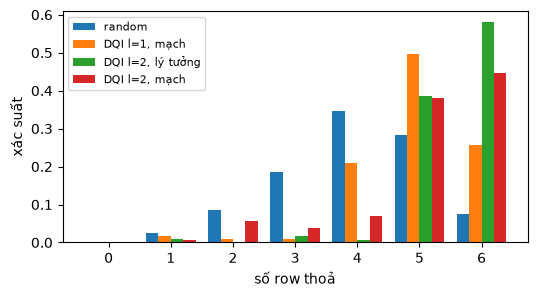

In [16]:
fig, ax = plt.subplots(figsize=(6, 3))
levels = np.arange(lin.m + 1)
for i, (name, P) in enumerate(dists.items()):
    ax.bar(levels + (i - 1.5) * 0.2, [P[s == v].sum() for v in levels], width=0.2, label=name)
ax.set_xlabel("số row thoả")
ax.set_ylabel("xác suất")
ax.legend(fontsize=8)
plt.show()

## 11. Lên dữ liệu ttqaoa: inst_01

**Mục tiêu.** Xem các bước trên thay đổi gì trên một instance thật của ttqaoa có quota.

**Input.** `ensembles/inst_01` của ttqaoa (8 section, 4 teacher, có quota).

**Output.** Nghiệm tối ưu chuẩn; kích thước, $d$, số qubit và $P(\text{tối ưu})$ của từng cách.

**Phương pháp.**
- Các formulation có hàm mục tiêu khác nhau, nên mọi cách được chấm bằng một thước đo chung: $V(a)$, số constraint gốc mà lịch $a$ vi phạm (eligibility, conflict, quota). Lịch tối ưu là lịch có $V=V^\star$, tìm bằng vét cạn và kiểm lại bằng CP-SAT.
- Formulation teacher-index của phần 3 (không có quota): mạch quá nhiều qubit để mô phỏng, nên dùng trạng thái lý tưởng. Ở $\ell=1$ trạng thái này trùng với mạch khi $\varepsilon_1=0$, như phần 10 đã kiểm trên ví dụ nhỏ.
- Formulation nhị phân $x_{s,l}$ có quota cứng, đã gộp các row trùng hệ số (DQITT-003): $\mathbb{F}_p^{16}$ quá lớn để liệt kê, nên dùng công thức đóng $\ell=1$ trên các vector 0/1.
- Random trên các teacher eligible, và QAOA của ttqaoa đọc từ `results/runs_to_optimal/ensembles.csv` (DQITT-005); QAOA không chạy lại ở đây vì mỗi lần tối ưu mất vài phút.

In [17]:
inst01 = load(paths.DATA / "ttqaoa" / "ensembles" / "inst_01")
print(len(inst01.sections), "section,", len(inst01.teachers), "teacher, quota (min, max):", inst01.quota)
print("eligible:", [sorted(E) for E in inst01.eligible])
v_star, best01 = optimum(inst01)
t0 = time.perf_counter()
v_cp, _ = cpsat_optimum(inst01)
print(f"V* = {v_star} ({len(best01)} lịch tối ưu); CP-SAT cho {v_cp} trong {time.perf_counter() - t0:.3f} s")

8 section, 4 teacher, quota (min, max): [(1, 2), (1, 2), (1, 2), (1, 4)]
eligible: [[0, 3], [0, 1], [1, 2], [0, 1], [2, 3], [0, 2], [2, 3], [0, 2]]


V* = 2 (182 lịch tối ưu); CP-SAT cho 2 trong 0.011 s


In [18]:
p_opt, qubits = {}, {}

E01 = np.array(list(product(*[sorted(E) for E in inst01.eligible])))
p_opt["random trên teacher eligible"] = (violations(inst01, E01) == v_star).mean()
qubits["random trên teacher eligible"] = 0

lin01 = build(inst01)
X01 = all_x(lin01.p, lin01.n)
opt01 = violations(inst01, np.where(X01 < len(inst01.teachers), X01, -1)) == v_star
eps01 = decoder_failure(lin01, 2)
print(f"teacher-index: p={lin01.p}, n={lin01.n}, m={lin01.m}, d={code_distance(lin01, 3)}, "
      f"ε_1={eps01[1]:.3f}, ε_2={eps01[2]:.3f}, qubit={n_wires(lin01)}")
p_opt["random trên F_5^8"], qubits["random trên F_5^8"] = opt01.mean(), 0
for l in (1, 2):
    psi, _, _ = ideal_state(lin01, l)
    name = f"DQI teacher-index l={l}" + (" (decoder lý tưởng)" if l == 2 else "")
    p_opt[name], qubits[name] = (np.abs(psi) ** 2)[opt01].sum(), n_wires(lin01)

teacher-index: p=5, n=8, m=24, d=3, ε_1=0.000, ε_2=0.582, qubit=120


In [19]:
linb, pairs = binary(inst01, "hard", merge=True)
Xb = np.array(list(product((0, 1), repeat=linb.n)))
decoded = [to_assignment(x, pairs, len(inst01.sections)) for x in Xb]
valid = np.array([a is not None for a in decoded])
Ab = np.array([a if a is not None else np.full(len(inst01.sections), -1) for a in decoded])
Pb = l1_probs(linb, l1_weights(linb), Xb)
print(f"nhị phân quota cứng: p={linb.p}, n={linb.n}, m={linb.m}, d={code_distance(linb, 3)}, qubit={n_wires(linb)}")
print(f"P(một lần đo là lịch 0/1 hợp lệ) = {Pb[valid].sum():.3g}")
p_opt["DQI nhị phân quota l=1"] = Pb[valid & (violations(inst01, Ab) == v_star)].sum()
qubits["DQI nhị phân quota l=1"] = n_wires(linb)

results = Path.cwd().parent / "results" / "runs_to_optimal" / "ensembles.csv"
for r in csv.DictReader(results.open()):
    if r["instance"] == "inst_01" and r["method"] in ("qaoa-rerun-p1", "qaoa-published-p5"):
        p_opt[f"{r['method']} (file kết quả)"], qubits[f"{r['method']} (file kết quả)"] = float(r["p_opt"]), int(r["qubits"])

print(f"\n{'cách':42s} {'qubit':>5s} {'P(tối ưu)':>10s} {'N95':>12s}")
for name in sorted(p_opt, key=p_opt.get, reverse=True):
    print(f"{name:42s} {qubits[name]:5d} {p_opt[name]:10.3g} {shots_to_hit(p_opt[name], 0.95):>12}")

nhị phân quota cứng: p=7, n=16, m=42, d=3, qubit=216
P(một lần đo là lịch 0/1 hợp lệ) = 1.15e-08

cách                                       qubit  P(tối ưu)          N95
qaoa-published-p5 (file kết quả)              16     0.0714           41
random trên teacher eligible                   0     0.0469           63
qaoa-rerun-p1 (file kết quả)                  16     0.0324           91
DQI teacher-index l=2 (decoder lý tưởng)     120    0.00751          398
DQI teacher-index l=1                        120    0.00243         1233
random trên F_5^8                              0   0.000466         6429
DQI nhị phân quota l=1                       216    4.1e-10   7310121626


## 12. Tóm tắt

- **Dữ liệu tới bài toán.** 4 file CSV cho ra $E_s$ và 3 cặp conflict. Formulation có $p=3$, $n=4$, $m=6$ và đúng 6 lịch tối ưu, khớp NOTE-001 tính tay (phần 2, 3).
- **Từng stage của mạch khớp công thức.** Dicke cho $P(k)=w_k^2$; `load` cho đúng phân bố error và trả flag về 0; `syndrome` cho đúng phân bố của $B^Te$ (phần 6 đến 8).
- **Điểm nghẽn là giải mã.** Code có $d=3$: hai codeword trọng số 3 đến từ triangle $s_0s_1s_2$ và từ cạnh $s_0s_1$ cộng hai row eligibility (phần 4). Ở $\ell=1$ bảng tra luôn đúng và mạch trùng trạng thái lý tưởng. Ở $\ell=2$, $\varepsilon_2=0.53$, thanh ghi error chỉ về 0 với xác suất 0.90, và $P(\text{tối ưu})$ của mạch là 0.447 so với 0.580 nếu decoder không sai (phần 9, 10).
- **Công thức trọng số của Jordan et al. không dùng được ở đây.** Mọi $|F_i|$ bằng 2 nhưng $2\ell+1<d$ không thoả, và công thức dự đoán $\langle s\rangle/m=0.8333$ ở $\ell=1$ trong khi trạng thái thật cho 0.8219 (phần 5).
- **Trên ví dụ nhỏ, DQI cần ít lần đo hơn random:** $N_{95}$ bằng 11 ở $\ell=1$ so với 39 (phần 10).
- **Trên inst_01 có quota (phần 11):** CP-SAT ra nghiệm tối ưu trong 0.01 giây. Mạch DQI cần 120 qubit (không quota) hoặc 216 qubit (có quota). DQI không quota ở $\ell=1$ cần 1,233 lần đo để có 95% khả năng thấy lịch tối ưu, nhiều hơn random trên teacher eligible (63) và QAOA 16 qubit của ttqaoa (41 và 91). Bản có quota chỉ ra một lịch 0/1 hợp lệ với xác suất khoảng $10^{-8}$.

Kết quả trên cả 20 instance ensembles: RES-001.